# Self-Supervised Learning pada RCAEval: RUN, TS2Vec, dan TimeMAE

Notebook ini mengimplementasikan plan SSL untuk dataset
[`phamquiluan/RCAEval`](https://huggingface.co/datasets/phamquiluan/RCAEval)
dengan `root_cause_service` sebagai ground truth (kelas).

**Alur:**
1. Load data **RE1 saja**, dijalankan **per sistem** (`RE1-OB`, `RE1-SS`, `RE1-TT`) dengan arsitektur dan hyperparameter yang sama.
   Rapikan anomali, buang kanal milik service yang bukan kelas, sejajarkan kolom metrik, normalisasi.
2. Split berkelompok (anti-bocor): `easy`, `medium`, atau `hard`.
3. Pretraining tanpa label pada window deret waktu: **TS2Vec**, **TimeMAE-mini**, **RUN-adapted**.
4. Representasi case = embedding window faulty dikurangi embedding window normal.
5. Linear probe untuk klasifikasi service + kurva label-efficiency.
6. Pembanding: fitur statistik, encoder random-init, model supervised dari nol, dan **RUN-native** (opsional, via RCAEval).
7. Kesimpulan.

**Catatan kejujuran implementasi (baca sebelum membandingkan angka):**
- **TS2Vec** memakai repo resmi (`yuezhihan/ts2vec`).
- **TimeMAE-mini** adalah re-implementasi ringkas di notebook ini (encoder terdekoupel yang hanya melihat patch tampak, regresi representasi dengan target EMA, dan klasifikasi codeword dengan codebook EMA). Ini bukan repo resmi TimeMAE. Untuk angka yang mau dipublikasikan, ekspor window ke repo resmi dan bandingkan.
- **RUN-adapted** hanya mengambil tahap contrastive tanpa negative pair (gaya SimSiam) sebagai encoder representasi. Tahap neural Granger causal discovery + PageRank tidak ada di sini. Versi utuhnya adalah **RUN-native** (sel opsional memakai implementasi di RCAEval).
- Jalankan dulu dengan `DRY_RUN=True` (data sintetis, tanpa internet) untuk memastikan pipeline jalan, lalu ganti ke data asli.

## 1. Setup

In [2]:
# Jalankan sekali (Colab/Kaggle). Lewati bila environment sudah siap.
%pip -q install pandas pyarrow huggingface_hub scikit-learn matplotlib tqdm
# torch biasanya sudah ada di Colab. Kalau belum: %pip -q install torch

# TS2Vec resmi (dipakai lewat sys.path)
!git clone -q https://github.com/yuezhihan/ts2vec.git ts2vec_repo 2>/dev/null || echo "ts2vec_repo sudah ada"

# RCAEval hanya untuk RUN-native (opsional, bagian 8). Boleh dilewati.
# %pip -q install "RCAEval[default]"


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
ts2vec_repo sudah ada


In [3]:
import os, sys, math, random, time, copy, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score
warnings.filterwarnings("ignore")

try:
    from tqdm.auto import tqdm
except Exception:
    tqdm = lambda x, **k: x

try:
    import torch, torch.nn as nn, torch.nn.functional as F
    HAS_TORCH = True
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except Exception as e:
    HAS_TORCH, DEVICE = False, "cpu"
    print("PERINGATAN: torch tidak ditemukan ->", e)

CFG = dict(
    SYSTEMS     = ["RE1-OB", "RE1-SS", "RE1-TT"],   # hanya RE1; tiap sistem dijalankan terpisah, arsitektur & hyperparameter sama
    DATASET     = None,       # sistem yang sedang diproses, diisi otomatis oleh prepare_system()
    DRY_RUN     = False,      # True = data sintetis, tanpa internet (smoke test pipeline)
    QUICK       = True,       # True = epoch/window kecil untuk uji cepat
    SPLIT       = "medium",   # easy | medium | hard
    CASE_REPR   = "diff",     # diff = faulty-normal | fault | concat
    MODELS      = ["stat", "random_ts2vec", "ts2vec", "timemae_mini", "runcl_mini", "sup_conv"],
    LABEL_FRACS = [0.1, 0.2, 0.5, 1.0],   # min. 1 case per kelas
    WIN         = 128,        # panjang window (detik, sampling RCAEval = 1 s)
    PATCH       = 8,          # ukuran patch TimeMAE-mini (WIN harus habis dibagi PATCH)
    CLIP        = 10.0,       # clip z-score
    PRUNE_CHANNELS = True,    # buang kanal milik service yang bukan kelas di RE1 (mis. frontend, emailservice)
    DATA_DIR    = "rcaeval_data",
    HF_REPO     = "phamquiluan/RCAEval",
)
if CFG["QUICK"]:
    CFG.update(SEEDS=[0], PRE_WIN=24, EVAL_WIN=8, TS2VEC_EPOCHS=3,
               MAE_EPOCHS=15, CL_EPOCHS=15, SUP_EPOCHS=15)
else:
    CFG.update(SEEDS=[0, 1, 2], PRE_WIN=80, EVAL_WIN=16, TS2VEC_EPOCHS=20,
               MAE_EPOCHS=60, CL_EPOCHS=60, SUP_EPOCHS=60)
assert CFG["WIN"] % CFG["PATCH"] == 0
assert all(s.startswith("RE1-") for s in CFG["SYSTEMS"]), "hanya RE1 yang dipakai"

def set_seed(s):
    random.seed(s); np.random.seed(s)
    if HAS_TORCH:
        torch.manual_seed(s)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(s)

print("device:", DEVICE, "| torch:", HAS_TORCH)

device: cpu | torch: True


## 2. Data

Hal penting yang ditangani di sini (berdasarkan isi dataset):
- Nama service **spesifik per sistem**, jadi tiap sistem RE1 (`RE1-OB`, `RE1-SS`, `RE1-TT`) dijalankan terpisah dengan arsitektur dan hyperparameter yang sama. Hasil digabung di akhir untuk perbandingan lintas sistem.
- Tiap sistem RE1 hanya punya 5 kelas `root_cause_service`. Service lain (mis. `frontend`, `emailservice`, `redis`) tidak pernah menjadi akar masalah di RE1, jadi **kanal metriknya dibuang** (`PRUNE_CHANNELS`). Kanal pendamping seperti `carts-db` dan `ts-*-mongo` ikut terbuang karena prefix-nya bukan kelas.
- Case rusak dibuang: seri lebih pendek dari `WIN` atau tanpa periode faulty (mis. `re1ob_productcatalogservice_cpu_3`: 63 detik, 0 titik faulty).
- Jumlah metrik berbeda antar case (mis. 49 s.d. 59 di RE1-OB) -> kolom disatukan (union), yang hilang diisi 0 setelah normalisasi.
- Ada `inject_time` rusak (mis. `re1ob_currencyservice_loss_1` = 16.933.142) -> diganti titik tengah seri (RE1 menyuntik fault di tengah).
- Ada kolom `time` ganda di sebagian case RE1-OB -> kolom duplikat dibuang.
- Normalisasi z-score memakai statistik **periode normal** (sebelum `inject_time`) per case.

In [4]:
def prefix_of(dataset):          # "RE1-OB" -> "re1ob"
    return dataset.replace("-", "").lower()

def service_of(col):             # "adservice_cpu" -> "adservice"
    return col.split("_")[0]

def fix_inject(inject, t0, t1, n):
    # inject_time rusak/di luar rentang -> titik tengah seri
    if inject is None or not (t0 < inject < t1):
        return int(t0 + (n - 1) // 2)
    return int(inject)

def preprocess_case(df, inject_time, all_cols):
    df = df.sort_values("time").reset_index(drop=True)
    t = df["time"].to_numpy(dtype=np.int64)
    X = (df.drop(columns=["time"]).astype(np.float64)
           .replace([np.inf, -np.inf], np.nan).ffill().bfill())
    inject_time = fix_inject(inject_time, t[0], t[-1], len(t))
    inj = int(np.clip(np.searchsorted(t, inject_time), 8, len(t) - 8))
    ref = X.iloc[:inj]                                  # periode normal
    sd = ref.std()
    sd = sd.where(sd > 1e-8, X.std())                   # fallback: std seluruh seri
    sd = sd.where(sd > 1e-8, 1.0)
    Z = ((X - ref.mean()) / sd).clip(-CFG["CLIP"], CFG["CLIP"])
    Z = Z.reindex(columns=all_cols).fillna(0.0)         # sejajarkan kolom
    return Z.to_numpy(np.float32), inj

# ---------- sumber data asli (Hugging Face)
def load_index():
    from huggingface_hub import hf_hub_download
    p = hf_hub_download(CFG["HF_REPO"], "cases.parquet", repo_type="dataset")
    return pd.read_parquet(p)

def download_cases(prefix):
    from huggingface_hub import snapshot_download
    return snapshot_download(
        repo_id=CFG["HF_REPO"], repo_type="dataset", local_dir=CFG["DATA_DIR"],
        allow_patterns=[f"{prefix}*/metrics.parquet", f"{prefix}*/inject_time.txt"])

def read_case(case_dir, inject_fallback):
    df = pd.read_parquet(case_dir / "metrics.parquet")
    df = df.loc[:, ~df.columns.duplicated()]            # kolom 'time' ganda di sebagian RE1-OB
    f = case_dir / "inject_time.txt"
    inj = inject_fallback
    if f.exists():
        try:
            inj = int(float(f.read_text().strip()))
        except Exception:
            pass
    return df, inj

def schema_cols(case_dir):
    import pyarrow.parquet as pq
    names = pq.read_schema(case_dir / "metrics.parquet").names
    return [c for c in dict.fromkeys(names) if c != "time"]

# ---------- sumber data sintetis (DRY_RUN)
def make_synthetic(n_svc=5, faults=("cpu", "mem", "delay", "loss"), reps=5, ch=6, T=721, seed=0):
    rng = np.random.default_rng(seed)
    svcs = [f"svc{i}" for i in range(n_svc)]
    cols = [f"{s}_m{j}" for s in svcs for j in range(ch)]
    rows, raw, t0, k = [], {}, 1_690_000_000, 0
    for si, s in enumerate(svcs):
        for fi, f in enumerate(faults):
            for r in range(1, reps + 1):
                case = f"syn_{s}_{f}_{r}"
                X = rng.normal(0, 1, (T, len(cols))).cumsum(0) * 0.05 + rng.normal(0, 1, (T, len(cols)))
                X = X * rng.uniform(0.5, 5, len(cols)) + rng.uniform(0, 100, len(cols))
                inj = T // 2
                sl = slice(si * ch, (si + 1) * ch)
                wave = np.sin(np.linspace(0, 6 * (fi + 1), T - inj))[:, None]
                X[inj:, sl] += (2 + fi) * wave * rng.uniform(0.5, 1.5, ch) * X[:inj, sl].std(0)
                df = pd.DataFrame(X, columns=cols)
                df.insert(0, "time", t0 + np.arange(T))
                if f == "delay":
                    df = df.drop(columns=[cols[-1]])      # uji penyejajaran kolom
                inj_t = t0 + inj if k > 0 else 12345      # case pertama: inject_time rusak
                raw[case] = (df, inj_t); k += 1
                rows.append(dict(case=case, dataset="SYN", root_cause_service=s, fault=f,
                                 repetition=r, inject_time=inj_t))
    return pd.DataFrame(rows), raw

DATA, DATA_ROOT = {}, None

def load_all():
    global DATA, DATA_ROOT
    if CFG["DRY_RUN"]:
        idx, raw = make_synthetic()
        get = lambda c: raw[c]
        cols_of = lambda c: [x for x in raw[c][0].columns if x != "time"]
    else:
        idx = load_index()
        idx = idx[idx.dataset == CFG["DATASET"]].reset_index(drop=True)
        assert len(idx) > 0, f"dataset {CFG['DATASET']} tidak ditemukan di cases.parquet"
        DATA_ROOT = download_cases(prefix_of(CFG["DATASET"]))
        inj_map = dict(zip(idx.case, idx.inject_time))
        get = lambda c: read_case(Path(DATA_ROOT) / c, inj_map[c])
        cols_of = lambda c: schema_cols(Path(DATA_ROOT) / c)
    # case rusak: seri lebih pendek dari WIN atau tanpa periode faulty
    if {"n_timesteps", "faulty_timesteps"} <= set(idx.columns):
        bad = (idx.n_timesteps < CFG["WIN"]) | (idx.faulty_timesteps <= 0)
        if bad.any():
            print("case dibuang (seri < WIN atau tanpa periode faulty):", list(idx.case[bad]))
        idx = idx[~bad].reset_index(drop=True)
    # kelas dari indeks; kanal service yang bukan kelas dibuang
    classes = sorted(set(idx.root_cause_service.astype(str)))
    union = sorted({c for case in idx.case for c in cols_of(case)})
    keep = lambda c: (not CFG["PRUNE_CHANNELS"]) or service_of(c) in classes
    all_cols = [c for c in union if keep(c)]
    dropped = sorted({service_of(c) for c in union if not keep(c)})
    lost = [k for k in classes if not any(service_of(c) == k for c in all_cols)]
    assert not lost, f"kelas tanpa kanal metrik: {lost}"
    Zs, injs = [], []
    for case in tqdm(list(idx.case), desc="preprocess"):
        df, inj_t = get(case)
        Z, inj = preprocess_case(df, inj_t, all_cols)
        Zs.append(Z); injs.append(inj)
    y = idx.root_cause_service.to_numpy().astype(str)
    DATA = dict(idx=idx, Z=Zs, inj=np.array(injs), cols=all_cols, y=y,
                classes=classes, fault=idx.fault.to_numpy().astype(str),
                rep=idx.repetition.to_numpy().astype(int), dropped=dropped, n_union=len(union))
    return DATA

SYS_INFO = {}

def prepare_system(name):
    # muat satu sistem; sel/fungsi berikutnya memakai DATA milik sistem ini
    CFG["DATASET"] = name
    load_all()
    n, C = len(DATA["Z"]), len(DATA["cols"])
    SYS_INFO[name] = dict(n_case=n, n_channel=C, n_union=DATA["n_union"], n_class=len(DATA["classes"]),
                          classes=DATA["classes"], dropped=DATA["dropped"])
    print(f"{name}: {n} case | {C} kanal (dari {DATA['n_union']}) | {len(DATA['classes'])} kelas: {DATA['classes']}")
    if DATA["dropped"]:
        d = DATA["dropped"]
        print(f"kanal {len(d)} service non-kelas dibuang:", d[:12], "..." if len(d) > 12 else "")
    print("chance level (acc):", round(1 / len(DATA["classes"]), 3))
    display(pd.crosstab(DATA["y"], DATA["fault"]))
    return DATA

prepare_system("SYN" if CFG["DRY_RUN"] else CFG["SYSTEMS"][0])   # pratinjau sistem pertama

Fetching 250 files: 100%|██████████| 250/250 [00:00<00:00, 1633.93it/s]


case dibuang (seri < WIN atau tanpa periode faulty): ['re1ob_productcatalogservice_cpu_3']


preprocess: 100%|██████████| 124/124 [00:01<00:00, 111.12it/s]

RE1-OB: 124 case | 39 kanal (dari 86) | 5 kelas: ['adservice', 'cartservice', 'checkoutservice', 'currencyservice', 'productcatalogservice']
kanal 10 service non-kelas dibuang: ['PassthroughCluster', 'emailservice', 'frontend', 'frontend-check', 'frontend-external', 'main', 'paymentservice', 'recommendationservice', 'redis', 'shippingservice'] 
chance level (acc): 0.2


col_0,cpu,delay,disk,loss,mem
row_0,,,,,
adservice,5,5,5,5,5
cartservice,5,5,5,5,5
checkoutservice,5,5,5,5,5
currencyservice,5,5,5,5,5
productcatalogservice,4,5,5,5,5


{'idx':                                   case dataset suite system      system_name  \
 0                re1ob_adservice_cpu_1  RE1-OB   RE1     ob  Online Boutique   
 1                re1ob_adservice_cpu_2  RE1-OB   RE1     ob  Online Boutique   
 2                re1ob_adservice_cpu_3  RE1-OB   RE1     ob  Online Boutique   
 3                re1ob_adservice_cpu_4  RE1-OB   RE1     ob  Online Boutique   
 4                re1ob_adservice_cpu_5  RE1-OB   RE1     ob  Online Boutique   
 ..                                 ...     ...   ...    ...              ...   
 119  re1ob_productcatalogservice_mem_1  RE1-OB   RE1     ob  Online Boutique   
 120  re1ob_productcatalogservice_mem_2  RE1-OB   RE1     ob  Online Boutique   
 121  re1ob_productcatalogservice_mem_3  RE1-OB   RE1     ob  Online Boutique   
 122  re1ob_productcatalogservice_mem_4  RE1-OB   RE1     ob  Online Boutique   
 123  re1ob_productcatalogservice_mem_5  RE1-OB   RE1     ob  Online Boutique   
 
         root_cause

## 3. Split anti-bocor dan windowing

Lima repetisi per pasangan (service, fault) hampir duplikat, jadi split acak per window/case akan bocor.
- `easy`: 5-fold stratified per service.
- `medium`: train repetisi awal (~60%), test repetisi akhir.
- `hard`: leave-one-fault-type-out (train pada jenis fault lain, test pada jenis fault yang ditahan).

Pretraining hanya memakai window dari **case train** pada split yang sedang dipakai.

In [5]:
def make_splits(scheme, seed=0):
    y, rep, fault = DATA["y"], DATA["rep"], DATA["fault"]
    ids = np.arange(len(y))
    if scheme == "easy":
        _, cnt = np.unique(y, return_counts=True)
        skf = StratifiedKFold(n_splits=int(min(5, cnt.min())), shuffle=True, random_state=seed)
        return [(f"easy-f{k}", tr, te) for k, (tr, te) in enumerate(skf.split(ids, y))]
    if scheme == "medium":
        cut = math.ceil(rep.max() * 0.6)
        return [("medium", ids[rep <= cut], ids[rep > cut])]
    if scheme == "hard":
        return [(f"hard-{f}", ids[fault != f], ids[fault == f]) for f in sorted(set(fault))]
    raise ValueError(scheme)

def starts_evenly(lo, hi, k):
    hi = max(hi, lo)
    return np.unique(np.linspace(lo, hi, k).round().astype(int))

def get_windows(Z, starts, L):
    T, out = len(Z), []
    for s in starts:
        s = int(min(max(s, 0), max(T - L, 0)))
        w = Z[s:s + L]
        if len(w) < L:
            w = np.pad(w, ((0, L - len(w)), (0, 0)), mode="edge")
        out.append(w)
    return np.stack(out)

def eval_windows(i, k=None):
    # window normal (sebelum inject) dan faulty (setelah inject) untuk case i
    k = k or CFG["EVAL_WIN"]; L = CFG["WIN"]
    Z, inj = DATA["Z"][i], DATA["inj"][i]
    sn = starts_evenly(0, inj - L, k)
    sf = starts_evenly(inj, len(Z) - L, k)
    return get_windows(Z, sn, L), get_windows(Z, sf, L)

def pretrain_windows(case_ids, per_case, rng):
    L, out = CFG["WIN"], []
    for i in case_ids:
        Z = DATA["Z"][i]
        st = rng.integers(0, max(len(Z) - L, 0) + 1, size=per_case)
        out.append(get_windows(Z, st, L))
    return np.concatenate(out).astype(np.float32)

for name, tr, te in make_splits(CFG["SPLIT"]):
    print(f"{name:14s} train={len(tr):3d} test={len(te):3d} | kelas di test: {len(set(DATA['y'][te]))}")

medium         train= 74 test= 50 | kelas di test: 5


## 4. Evaluasi (linear probe) dan baseline statistik

Semua model memakai **probe yang sama**: `StandardScaler` + `LogisticRegression` pada representasi case.
Metrik: accuracy, macro-F1, dan Top-3 accuracy. Label-efficiency: probe dilatih dengan sebagian label train
(minimal 1 case per kelas). Karena jumlah case kecil, pecahan label yang dipakai 10/20/50/100% (bukan 1%).

In [6]:
def score_proba(y_true, proba, classes_):
    classes_ = np.asarray(classes_)
    pred = classes_[proba.argmax(1)]
    k = min(3, len(classes_))
    topk = np.argsort(-proba, axis=1)[:, :k]
    top3 = float(np.mean([yt in classes_[row] for yt, row in zip(y_true, topk)]))
    sc = dict(acc=accuracy_score(y_true, pred),
              macro_f1=f1_score(y_true, pred, average="macro"), top3=top3)
    return sc, (pred == y_true)

def subsample_train(tr, y, frac, seed):
    if frac >= 1.0:
        return tr
    rng, keep = np.random.default_rng(seed), []
    for c in np.unique(y[tr]):
        ids = tr[y[tr] == c]
        keep.extend(rng.choice(ids, max(1, int(round(frac * len(ids)))), replace=False))
    return np.array(sorted(keep))

def probe(R, tr, te, y, frac, seed):
    sub = subsample_train(tr, y, frac, seed)
    clf = make_pipeline(StandardScaler(),
                        LogisticRegression(max_iter=3000, C=1.0, class_weight="balanced"))
    clf.fit(R[sub], y[sub])
    sc, ok = score_proba(y[te], clf.predict_proba(R[te]), clf.classes_)
    return sc, ok, sub

def stat_features():
    # baseline tanpa SSL: statistik z-score periode faulty per kanal
    out = []
    for Z, inj in zip(DATA["Z"], DATA["inj"]):
        Zf = Z[inj:]
        out.append(np.concatenate([Zf.mean(0), np.abs(Zf).max(0), Zf.std(0)]))
    return np.stack(out).astype(np.float32)

def embed_all(encode_fn):
    # embedding semua case -> representasi case (n_case, d)
    WN, WF, nN, nF = [], [], [], []
    for i in range(len(DATA["Z"])):
        wn, wf = eval_windows(i)
        WN.append(wn); WF.append(wf); nN.append(len(wn)); nF.append(len(wf))
    EN = np.split(encode_fn(np.concatenate(WN)), np.cumsum(nN)[:-1])
    EF = np.split(encode_fn(np.concatenate(WF)), np.cumsum(nF)[:-1])
    mN = np.stack([e.mean(0) for e in EN]); mF = np.stack([e.mean(0) for e in EF])
    mode = CFG["CASE_REPR"]
    if mode == "diff":
        return mF - mN
    if mode == "fault":
        return mF
    return np.concatenate([mF, mF - mN], axis=1)

STAT_R = stat_features()
print("fitur statistik:", STAT_R.shape)

fitur statistik: (124, 117)


## 5. Model SSL

Semua embedder punya antarmuka sama: `fit(windows)` lalu `encode(windows) -> (n, d)`;
input window berbentuk `(N, WIN, C)`.

### 5.1 TS2Vec (repo resmi)
Contrastive hierarkis (temporal + instance-wise). `random_ts2vec` = arsitektur sama tanpa pretraining
(kontrol: apakah pretraining benar-benar membantu?).

In [7]:
if HAS_TORCH:
    class TS2VecEmbedder:
        def __init__(self, C, epochs, trained=True):
            if "ts2vec_repo" not in sys.path:
                sys.path.insert(0, "ts2vec_repo")
            from ts2vec import TS2Vec
            self.epochs, self.trained = epochs, trained
            self.m = TS2Vec(input_dims=C, output_dims=320, hidden_dims=64, depth=10,
                            device=DEVICE, batch_size=16)
        def fit(self, W):
            if self.trained and self.epochs > 0:
                self.m.fit(W, n_epochs=self.epochs, verbose=False)
            return self
        def encode(self, W):
            return self.m.encode(W, encoding_window="full_series", batch_size=64)
else:
    print('torch tidak tersedia -> cell ini dilewati')

### 5.2 TimeMAE-mini
Re-implementasi ringkas gaya TimeMAE: window dipotong jadi patch, sebagian patch di-mask,
**encoder hanya melihat patch tampak** (terdekoupel), decoder memprediksi untuk posisi yang di-mask:
- *Masked Representation Regression (MRR)*: regresi ke representasi target dari encoder EMA yang melihat sinyal utuh.
- *Masked Codeword Classification (MCC)*: klasifikasi ke codeword (codebook diperbarui EMA) dari representasi target.

Ini bukan kode resmi; bandingkan dengan repo resmi TimeMAE bila hasilnya akan dilaporkan.

In [8]:
if HAS_TORCH:
    def _tf(d, heads, depth, ff=4):
        layer = nn.TransformerEncoderLayer(d_model=d, nhead=heads, dim_feedforward=d * ff, dropout=0.1,
                                           activation="gelu", batch_first=True, norm_first=True)
        return nn.TransformerEncoder(layer, num_layers=depth, enable_nested_tensor=False)

    class _Backbone(nn.Module):
        def __init__(self, C, patch, n_patch, d, depth, heads):
            super().__init__()
            self.embed = nn.Linear(C * patch, d)
            self.pos = nn.Parameter(torch.zeros(1, n_patch, d))
            nn.init.trunc_normal_(self.pos, std=0.02)
            self.enc = _tf(d, heads, depth)
            self.norm = nn.LayerNorm(d)
        def tokens(self, p):                       # semua patch: (B,N,d)
            return self.norm(self.enc(self.embed(p) + self.pos))
        def visible(self, p, vis_ids):             # hanya patch tampak: (B,n_vis,d)
            x = self.embed(p) + self.pos
            x = torch.gather(x, 1, vis_ids.unsqueeze(-1).expand(-1, -1, x.size(-1)))
            return self.norm(self.enc(x))

    class TimeMAEMini(nn.Module):
        def __init__(self, C, L, patch=8, d=128, depth=3, heads=4, mask_ratio=0.6, ema=0.99,
                     n_codes=128, w_mcc=0.5, lr=5e-4, epochs=30, bs=64, device="cpu"):
            super().__init__()
            self.C, self.L, self.patch, self.N = C, L, patch, L // patch
            self.n_mask = max(1, int(round(self.N * mask_ratio)))
            self.n_vis = self.N - self.n_mask
            self.ema, self.w_mcc, self.lr, self.epochs, self.bs, self.device = ema, w_mcc, lr, epochs, bs, device
            self.online = _Backbone(C, patch, self.N, d, depth, heads)
            self.target = copy.deepcopy(self.online)
            for p_ in self.target.parameters():
                p_.requires_grad_(False)
            self.dec = _tf(d, heads, 1)
            self.mask_token = nn.Parameter(torch.zeros(1, 1, d))
            nn.init.trunc_normal_(self.mask_token, std=0.02)
            self.pred = nn.Linear(d, d)
            self.cls = nn.Linear(d, n_codes)
            self.register_buffer("codebook", F.normalize(torch.randn(n_codes, d), dim=-1))
            self.register_buffer("cb_cnt", torch.ones(n_codes))
            self.register_buffer("cb_sum", self.codebook.clone())

        def train(self, mode=True):
            super().train(mode)
            self.target.eval()                    # target selalu eval (tanpa dropout)
            return self

        def _patchify(self, x):                   # (B,L,C) -> (B,N,patch*C)
            return x.reshape(x.size(0), self.N, self.patch * self.C)

        @torch.no_grad()
        def _update_codebook(self, t, code, decay=0.99):
            K = self.codebook.size(0)
            oh = F.one_hot(code, K).float()
            self.cb_cnt.mul_(decay).add_(oh.sum(0), alpha=1 - decay)
            self.cb_sum.mul_(decay).add_(oh.t() @ F.normalize(t, dim=-1), alpha=1 - decay)
            self.codebook.copy_(F.normalize(self.cb_sum / self.cb_cnt.clamp_min(1e-5).unsqueeze(-1), dim=-1))

        @torch.no_grad()
        def _ema(self):
            for tp, op in zip(self.target.parameters(), self.online.parameters()):
                tp.mul_(self.ema).add_(op.detach(), alpha=1 - self.ema)

        def loss(self, x):
            B = x.size(0)
            p = self._patchify(x)
            ids = torch.rand(B, self.N, device=x.device).argsort(dim=1)
            vis_ids, msk_ids = ids[:, :self.n_vis], ids[:, self.n_vis:]
            h = self.online.visible(p, vis_ids)                       # encoder: hanya patch tampak
            d = h.size(-1)
            pos = self.online.pos.expand(B, -1, -1)
            take = lambda t, i: torch.gather(t, 1, i.unsqueeze(-1).expand(-1, -1, d))
            dec_in = torch.cat([h + take(pos, vis_ids),
                                self.mask_token.expand(B, self.n_mask, -1) + take(pos, msk_ids)], dim=1)
            z = self.dec(dec_in)[:, self.n_vis:]                       # (B,n_mask,d)
            with torch.no_grad():
                t_m = take(self.target.tokens(p), msk_ids)             # target: sinyal utuh
                code = (F.normalize(t_m, dim=-1) @ self.codebook.t()).argmax(-1)
            l_mrr = F.mse_loss(self.pred(z), t_m)
            l_mcc = F.cross_entropy(self.cls(z).reshape(-1, self.cls.out_features), code.reshape(-1))
            if self.training:
                self._update_codebook(t_m.detach().reshape(-1, d), code.reshape(-1))
            return l_mrr + self.w_mcc * l_mcc

        def fit(self, W):
            self.to(self.device).train()
            X = torch.from_numpy(W.astype(np.float32))
            params = [p for n_, p in self.named_parameters() if not n_.startswith("target.")]
            opt = torch.optim.AdamW(params, lr=self.lr, weight_decay=1e-4)
            steps = max(1, math.ceil(len(X) / self.bs))
            sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=self.lr, total_steps=self.epochs * steps)
            for ep in range(self.epochs):
                perm = torch.randperm(len(X))
                for b in range(steps):
                    xb = X[perm[b * self.bs:(b + 1) * self.bs]].to(self.device)
                    loss = self.loss(xb)
                    opt.zero_grad(set_to_none=True)
                    loss.backward()
                    nn.utils.clip_grad_norm_(params, 1.0)
                    opt.step(); sched.step(); self._ema()
            return self

        @torch.no_grad()
        def encode(self, W, bs=128):
            self.eval(); out = []
            for i in range(0, len(W), bs):
                xb = torch.from_numpy(W[i:i + bs].astype(np.float32)).to(self.device)
                out.append(self.online.tokens(self._patchify(xb)).mean(1).cpu().numpy())
            return np.concatenate(out)
else:
    print('torch tidak tersedia -> cell ini dilewati')

### 5.3 RUN-adapted (contrastive tanpa negative pair)
RUN memakai contrastive learning **tanpa negative pairs** untuk memperkaya encoder sebelum tahap Granger.
Di sini diadaptasi sebagai encoder SimSiam-style (dua view dari crop + augmentasi berbeda, predictor, stop-gradient)
supaya bisa dibandingkan dengan TS2Vec dan TimeMAE di protokol linear probe yang sama.
Augmentasi dan arsitektur adalah pilihan saya, bukan kode asli RUN.

### 5.4 Pembanding supervised (`sup_conv`)
Encoder konvolusi yang sama, dilatih **dengan label** end-to-end pada window faulty. Prediksi case = rata-rata softmax window.

In [9]:
if HAS_TORCH:
    class _ConvEnc(nn.Module):
        def __init__(self, C, h=96, d=128, depth=4):
            super().__init__()
            self.inp = nn.Conv1d(C, h, 1)
            self.blocks = nn.ModuleList([
                nn.Sequential(nn.Conv1d(h, h, 5, padding=2 * 2 ** i, dilation=2 ** i),
                              nn.BatchNorm1d(h), nn.GELU()) for i in range(depth)])
            self.out = nn.Linear(2 * h, d)
        def forward(self, x):                      # x: (B,L,C)
            z = self.inp(x.transpose(1, 2))
            for blk in self.blocks:
                z = z + blk(z)
            return self.out(torch.cat([z.mean(-1), z.amax(-1)], dim=-1))

    class ContrastiveNoNegMini(nn.Module):
        def __init__(self, C, d=128, lr=1e-3, epochs=30, bs=64, crop=0.75, device="cpu"):
            super().__init__()
            self.f = _ConvEnc(C, d=d)
            self.g = nn.Sequential(nn.Linear(d, d), nn.BatchNorm1d(d), nn.GELU(), nn.Linear(d, d))
            self.h = nn.Sequential(nn.Linear(d, d // 2), nn.BatchNorm1d(d // 2), nn.GELU(), nn.Linear(d // 2, d))
            self.lr, self.epochs, self.bs, self.crop, self.device = lr, epochs, bs, crop, device

        def _view(self, x):
            B, L, C_ = x.shape
            Lc = max(8, int(L * self.crop))
            s = int(torch.randint(0, L - Lc + 1, (1,)))
            x = x[:, s:s + Lc]
            x = x * (1 + 0.1 * torch.randn(B, 1, C_, device=x.device))                 # scaling per kanal
            x = x + 0.05 * torch.randn_like(x)                                          # jitter
            x = x * (torch.rand(B, x.size(1), 1, device=x.device) > 0.15).float()      # time masking
            x = x * (torch.rand(B, 1, C_, device=x.device) > 0.10).float()             # channel dropout
            return x

        def loss(self, x):
            z1, z2 = self.g(self.f(self._view(x))), self.g(self.f(self._view(x)))
            p1, p2 = self.h(z1), self.h(z2)
            D = lambda p, z: -F.cosine_similarity(p, z.detach(), dim=-1).mean()       # stop-gradient
            return 0.5 * (D(p1, z2) + D(p2, z1))

        def fit(self, W):
            self.to(self.device).train()
            X = torch.from_numpy(W.astype(np.float32))
            opt = torch.optim.AdamW(self.parameters(), lr=self.lr, weight_decay=1e-4)
            steps = max(1, math.ceil(len(X) / self.bs))
            for ep in range(self.epochs):
                perm = torch.randperm(len(X))
                for b in range(steps):
                    idx = perm[b * self.bs:(b + 1) * self.bs]
                    if len(idx) < 2:
                        continue
                    loss = self.loss(X[idx].to(self.device))
                    opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            return self

        @torch.no_grad()
        def encode(self, W, bs=128):
            self.eval(); out = []
            for i in range(0, len(W), bs):
                xb = torch.from_numpy(W[i:i + bs].astype(np.float32)).to(self.device)
                out.append(self.f(xb).cpu().numpy())
            return np.concatenate(out)

    class SupConv(nn.Module):
        def __init__(self, C, K, d=128, lr=1e-3, epochs=30, bs=64, win_per_case=24, device="cpu"):
            super().__init__()
            self.f, self.head = _ConvEnc(C, d=d), nn.Linear(d, K)
            self.lr, self.epochs, self.bs, self.k, self.device = lr, epochs, bs, win_per_case, device

        def fit_cases(self, case_ids, y_enc):
            Ws, Ys = [], []
            for i, yy in zip(case_ids, y_enc):
                _, wf = eval_windows(i, self.k)
                Ws.append(wf); Ys.append(np.full(len(wf), yy))
            X = torch.from_numpy(np.concatenate(Ws).astype(np.float32))
            Y = torch.from_numpy(np.concatenate(Ys).astype(np.int64))
            self.to(self.device).train()
            opt = torch.optim.AdamW(self.parameters(), lr=self.lr, weight_decay=1e-2)
            steps = max(1, math.ceil(len(X) / self.bs))
            for ep in range(self.epochs):
                perm = torch.randperm(len(X))
                for b in range(steps):
                    idx = perm[b * self.bs:(b + 1) * self.bs]
                    if len(idx) < 2:
                        continue
                    xb = X[idx].to(self.device); xb = xb + 0.05 * torch.randn_like(xb)
                    loss = F.cross_entropy(self.head(self.f(xb)), Y[idx].to(self.device))
                    opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            return self

        @torch.no_grad()
        def predict_proba(self, case_ids):
            self.eval(); out = []
            for i in case_ids:
                _, wf = eval_windows(i)
                xb = torch.from_numpy(wf.astype(np.float32)).to(self.device)
                out.append(F.softmax(self.head(self.f(xb)), -1).mean(0).cpu().numpy())
            return np.stack(out)
else:
    print('torch tidak tersedia -> cell ini dilewati')

## 6. Menjalankan eksperimen

Untuk tiap sistem RE1 (diproses terpisah, arsitektur dan hyperparameter sama) dan tiap (seed, split): pretraining SSL pada window case train -> embed semua case -> linear probe
pada beberapa pecahan label. Model yang gagal (mis. repo TS2Vec belum di-clone) dilewati dengan pesan, bukan menghentikan notebook.

In [10]:
def build_embedder(name, C):
    if name == "random_ts2vec":
        return TS2VecEmbedder(C, epochs=0, trained=False)
    if name == "ts2vec":
        return TS2VecEmbedder(C, epochs=CFG["TS2VEC_EPOCHS"])
    if name == "timemae_mini":
        return TimeMAEMini(C, CFG["WIN"], patch=CFG["PATCH"], epochs=CFG["MAE_EPOCHS"], device=DEVICE)
    if name == "runcl_mini":
        return ContrastiveNoNegMini(C, epochs=CFG["CL_EPOCHS"], device=DEVICE)
    raise ValueError(name)

def run_experiments():
    rows, per_fault = [], []
    y, classes = DATA["y"], DATA["classes"]
    y_enc = np.array([classes.index(v) for v in y])
    C = len(DATA["cols"])
    fmax = max(CFG["LABEL_FRACS"])

    def record(model, split, seed, frac, sc, ok, te, n_train):
        rows.append(dict(model=model, split=split, seed=seed, frac=frac, n_train=n_train, **sc))
        if frac == fmax:
            per_fault.extend(dict(model=model, split=split, seed=seed,
                                  fault=DATA["fault"][i], correct=bool(c)) for i, c in zip(te, ok))

    for seed in CFG["SEEDS"]:
        for split, tr, te in make_splits(CFG["SPLIT"], seed):
            rng = np.random.default_rng(seed)
            Wpre = None
            for mname in CFG["MODELS"]:
                t0 = time.time()
                try:
                    if mname == "stat":
                        R = stat_features()
                    elif not HAS_TORCH:
                        print(f"[skip] {mname}: torch tidak tersedia"); continue
                    elif mname == "sup_conv":
                        for frac in CFG["LABEL_FRACS"]:
                            set_seed(seed)
                            sub = subsample_train(tr, y, frac, seed)
                            m = SupConv(C, len(classes), epochs=CFG["SUP_EPOCHS"], device=DEVICE)
                            m.fit_cases(sub, y_enc[sub])
                            sc, ok = score_proba(y[te], m.predict_proba(te), classes)
                            record(mname, split, seed, frac, sc, ok, te, len(sub))
                        print(f"[ok] seed={seed} {split} {mname} ({time.time()-t0:.0f}s)"); continue
                    else:
                        set_seed(seed)
                        if Wpre is None:
                            Wpre = pretrain_windows(tr, CFG["PRE_WIN"], rng)
                        emb = build_embedder(mname, C).fit(Wpre)
                        R = embed_all(emb.encode)
                    for frac in CFG["LABEL_FRACS"]:
                        sc, ok, sub = probe(R, tr, te, y, frac, seed)
                        record(mname, split, seed, frac, sc, ok, te, len(sub))
                    print(f"[ok] seed={seed} {split} {mname} ({time.time()-t0:.0f}s)")
                except Exception as e:
                    print(f"[GAGAL] {mname}: {type(e).__name__}: {e}")
    return pd.DataFrame(rows), pd.DataFrame(per_fault)

def run_all_systems():
    # tiap sistem dijalankan terpisah; arsitektur & hyperparameter sama (CFG), hanya jumlah kanal input yang menyesuaikan
    res, pf = [], []
    for name in (["SYN"] if CFG["DRY_RUN"] else CFG["SYSTEMS"]):
        print(f"\n===== {name} =====")
        prepare_system(name)
        r, p = run_experiments()
        res.append(r.assign(system=name)); pf.append(p.assign(system=name))
    return pd.concat(res, ignore_index=True), pd.concat(pf, ignore_index=True)

results, per_fault = run_all_systems()
results.head()


===== RE1-OB =====


Fetching 250 files: 100%|██████████| 250/250 [00:00<00:00, 1410.91it/s]


case dibuang (seri < WIN atau tanpa periode faulty): ['re1ob_productcatalogservice_cpu_3']


preprocess: 100%|██████████| 124/124 [00:00<00:00, 126.86it/s]

RE1-OB: 124 case | 39 kanal (dari 86) | 5 kelas: ['adservice', 'cartservice', 'checkoutservice', 'currencyservice', 'productcatalogservice']
kanal 10 service non-kelas dibuang: ['PassthroughCluster', 'emailservice', 'frontend', 'frontend-check', 'frontend-external', 'main', 'paymentservice', 'recommendationservice', 'redis', 'shippingservice'] 
chance level (acc): 0.2


col_0,cpu,delay,disk,loss,mem
row_0,,,,,
adservice,5,5,5,5,5
cartservice,5,5,5,5,5
checkoutservice,5,5,5,5,5
currencyservice,5,5,5,5,5
productcatalogservice,4,5,5,5,5


... (6 outputs left out)

RE1-TT: 125 case | 30 kanal (dari 241) | 5 kelas: ['ts-auth-service', 'ts-order-service', 'ts-route-service', 'ts-train-service', 'ts-travel-service']
kanal 59 service non-kelas dibuang: ['ts-admin-basic-info-service', 'ts-admin-order-service', 'ts-admin-route-service', 'ts-admin-travel-service', 'ts-admin-user-service', 'ts-assurance-mongo', 'ts-assurance-service', 'ts-auth-mongo', 'ts-avatar-service', 'ts-basic-service', 'ts-cancel-service', 'ts-config-mongo'] ...
chance level (acc): 0.2


col_0,cpu,delay,disk,loss,mem
row_0,,,,,
ts-auth-service,5,5,5,5,5
ts-order-service,5,5,5,5,5
ts-route-service,5,5,5,5,5
ts-train-service,5,5,5,5,5
ts-travel-service,5,5,5,5,5


[ok] seed=0 medium stat (0s)
[ok] seed=0 medium random_ts2vec (10s)
[ok] seed=0 medium ts2vec (88s)
[ok] seed=0 medium timemae_mini (24s)
[ok] seed=0 medium runcl_mini (121s)
[ok] seed=0 medium sup_conv (131s)


,model,split,seed,frac,n_train,acc,macro_f1,top3,system
0,stat,medium,0,0.1,9,0.34,0.338995,0.78,RE1-OB
1,stat,medium,0,0.2,15,0.68,0.694828,0.86,RE1-OB
2,stat,medium,0,0.5,39,0.96,0.959596,1.00,RE1-OB
3,stat,medium,0,1.0,74,1.00,1.000000,1.00,RE1-OB
4,random_ts2vec,medium,0,0.1,9,0.54,0.528657,0.86,RE1-OB


## 7. Hasil


########## RE1-OB: 124 case, 39 kanal, 5 kelas ##########


acc     macro_f1      top3    
                    mean std     mean std  mean std
model         frac                                 
random_ts2vec 0.1   0.54 NaN    0.529 NaN  0.86 NaN
              0.2   0.72 NaN    0.709 NaN  0.80 NaN
              0.5   0.92 NaN    0.919 NaN  1.00 NaN
              1.0   0.98 NaN    0.980 NaN  1.00 NaN
runcl_mini    0.1   0.44 NaN    0.448 NaN  0.92 NaN
              0.2   0.72 NaN    0.710 NaN  0.86 NaN
              0.5   0.98 NaN    0.980 NaN  1.00 NaN
              1.0   1.00 NaN    1.000 NaN  1.00 NaN
stat          0.1   0.34 NaN    0.339 NaN  0.78 NaN
              0.2   0.68 NaN    0.695 NaN  0.86 NaN
              0.5   0.96 NaN    0.960 NaN  1.00 NaN
              1.0   1.00 NaN    1.000 NaN  1.00 NaN
sup_conv      0.1   0.68 NaN    0.667 NaN  0.86 NaN
              0.2   0.70 NaN    0.700 NaN  0.90 NaN
              0.5   0.94 NaN    0.940 NaN  1.00 NaN
              1.0   1.00 NaN    1.000 NaN  1.00 NaN
timemae_mini  0.1   0.64 NaN    0.637 NaN  0.88 NaN
              0.2   0.68 NaN    0.701 NaN  0.90 NaN
              0.5   0.98 NaN    0.980 NaN  1.00 NaN
              1.0   0.94 NaN    0.940 NaN  1.00 NaN
ts2vec        0.1   0.52 NaN    0.539 NaN  0.74 NaN
              0.2   0.64 NaN    0.646 NaN  0.84 NaN
              0.5   0.90 NaN    0.900 NaN  1.00 NaN
              1.0   0.96 NaN    0.960 NaN  1.00 NaN

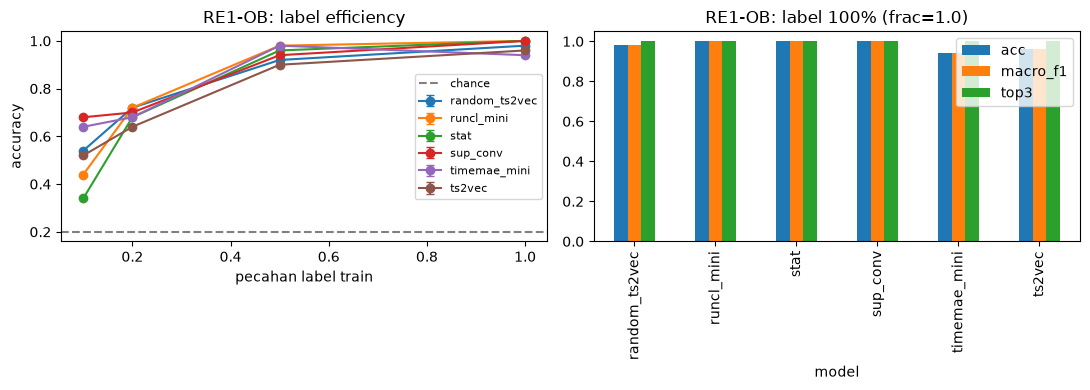

Accuracy per jenis fault (label penuh):


fault,cpu,delay,disk,loss,mem
model,,,,,
random_ts2vec,1.0,1.0,1.0,0.9,1.0
runcl_mini,1.0,1.0,1.0,1.0,1.0
stat,1.0,1.0,1.0,1.0,1.0
sup_conv,1.0,1.0,1.0,1.0,1.0
timemae_mini,1.0,1.0,1.0,0.7,1.0
ts2vec,1.0,1.0,1.0,0.8,1.0



########## RE1-SS: 125 case, 30 kanal, 5 kelas ##########


acc     macro_f1      top3    
                    mean std     mean std  mean std
model         frac                                 
random_ts2vec 0.1   0.84 NaN    0.823 NaN  0.96 NaN
              0.2   0.84 NaN    0.835 NaN  0.94 NaN
              0.5   0.90 NaN    0.898 NaN  1.00 NaN
              1.0   0.94 NaN    0.940 NaN  1.00 NaN
runcl_mini    0.1   0.86 NaN    0.852 NaN  0.98 NaN
              0.2   0.88 NaN    0.870 NaN  0.96 NaN
              0.5   0.88 NaN    0.883 NaN  1.00 NaN
              1.0   0.96 NaN    0.960 NaN  1.00 NaN
stat          0.1   0.70 NaN    0.650 NaN  0.90 NaN
              0.2   0.74 NaN    0.736 NaN  0.92 NaN
              0.5   0.94 NaN    0.941 NaN  1.00 NaN
              1.0   0.98 NaN    0.980 NaN  1.00 NaN
sup_conv      0.1   0.86 NaN    0.851 NaN  0.96 NaN
              0.2   0.88 NaN    0.874 NaN  0.96 NaN
              0.5   0.98 NaN    0.980 NaN  1.00 NaN
              1.0   0.98 NaN    0.980 NaN  1.00 NaN
timemae_mini  0.1   0.84 NaN    0.835 NaN  0.98 NaN
              0.2   0.88 NaN    0.875 NaN  0.90 NaN
              0.5   0.94 NaN    0.939 NaN  1.00 NaN
              1.0   0.96 NaN    0.960 NaN  1.00 NaN
ts2vec        0.1   0.68 NaN    0.684 NaN  0.92 NaN
              0.2   0.74 NaN    0.743 NaN  0.88 NaN
              0.5   0.86 NaN    0.852 NaN  0.98 NaN
              1.0   0.92 NaN    0.913 NaN  1.00 NaN

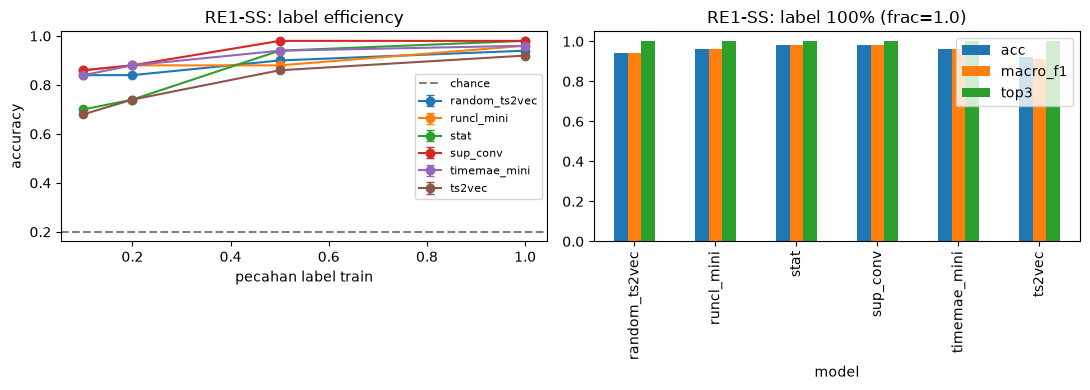

Accuracy per jenis fault (label penuh):


fault,cpu,delay,disk,loss,mem
model,,,,,
random_ts2vec,1.0,1.0,1.0,0.8,0.9
runcl_mini,1.0,1.0,1.0,0.9,0.9
stat,1.0,1.0,1.0,1.0,0.9
sup_conv,1.0,1.0,1.0,1.0,0.9
timemae_mini,1.0,1.0,1.0,0.9,0.9
ts2vec,1.0,0.8,1.0,0.8,1.0



########## RE1-TT: 125 case, 30 kanal, 5 kelas ##########


acc     macro_f1      top3    
                    mean std     mean std  mean std
model         frac                                 
random_ts2vec 0.1   0.78 NaN    0.790 NaN  1.00 NaN
              0.2   0.92 NaN    0.917 NaN  1.00 NaN
              0.5   0.94 NaN    0.940 NaN  1.00 NaN
              1.0   1.00 NaN    1.000 NaN  1.00 NaN
runcl_mini    0.1   0.86 NaN    0.855 NaN  1.00 NaN
              0.2   0.88 NaN    0.877 NaN  1.00 NaN
              0.5   0.96 NaN    0.960 NaN  1.00 NaN
              1.0   1.00 NaN    1.000 NaN  1.00 NaN
stat          0.1   0.74 NaN    0.744 NaN  0.96 NaN
              0.2   0.82 NaN    0.828 NaN  1.00 NaN
              0.5   0.92 NaN    0.914 NaN  0.96 NaN
              1.0   0.98 NaN    0.980 NaN  1.00 NaN
sup_conv      0.1   0.88 NaN    0.877 NaN  1.00 NaN
              0.2   0.90 NaN    0.899 NaN  1.00 NaN
              0.5   0.94 NaN    0.940 NaN  1.00 NaN
              1.0   1.00 NaN    1.000 NaN  1.00 NaN
timemae_mini  0.1   0.94 NaN    0.940 NaN  0.98 NaN
              0.2   0.96 NaN    0.960 NaN  1.00 NaN
              0.5   0.94 NaN    0.937 NaN  0.98 NaN
              1.0   1.00 NaN    1.000 NaN  1.00 NaN
ts2vec        0.1   0.62 NaN    0.631 NaN  1.00 NaN
              0.2   0.76 NaN    0.769 NaN  0.98 NaN
              0.5   0.94 NaN    0.940 NaN  1.00 NaN
              1.0   1.00 NaN    1.000 NaN  1.00 NaN

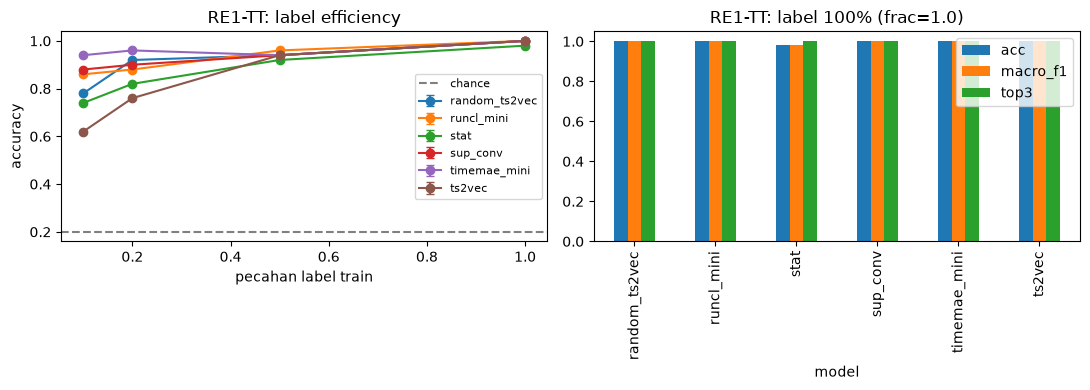

Accuracy per jenis fault (label penuh):


fault,cpu,delay,disk,loss,mem
model,,,,,
random_ts2vec,1.0,1.0,1.0,1.0,1.0
runcl_mini,1.0,1.0,1.0,1.0,1.0
stat,1.0,1.0,1.0,0.9,1.0
sup_conv,1.0,1.0,1.0,1.0,1.0
timemae_mini,1.0,1.0,1.0,1.0,1.0
ts2vec,1.0,1.0,1.0,1.0,1.0



acc pada label penuh (frac=1.0), model x sistem:


system,RE1-OB,RE1-SS,RE1-TT
model,,,
random_ts2vec,0.98,0.94,1.00
runcl_mini,1.00,0.96,1.00
stat,1.00,0.98,0.98
sup_conv,1.00,0.98,1.00
timemae_mini,0.94,0.96,1.00
ts2vec,0.96,0.92,1.00



macro_f1 pada label penuh (frac=1.0), model x sistem:


system,RE1-OB,RE1-SS,RE1-TT
model,,,
random_ts2vec,0.98,0.940,1.00
runcl_mini,1.00,0.960,1.00
stat,1.00,0.980,0.98
sup_conv,1.00,0.980,1.00
timemae_mini,0.94,0.960,1.00
ts2vec,0.96,0.913,1.00


In [11]:
if len(results) == 0:
    print("Belum ada hasil.")
else:
    for name, res in results.groupby("system", sort=False):
        info = SYS_INFO[name]
        print(f"\n########## {name}: {info['n_case']} case, {info['n_channel']} kanal, {info['n_class']} kelas ##########")
        summary = (res.groupby(["model", "frac"])[["acc", "macro_f1", "top3"]]
                      .agg(["mean", "std"]).round(3))
        display(summary)

        fig, ax = plt.subplots(1, 2, figsize=(11, 4))
        for m, g in res.groupby("model"):
            s = g.groupby("frac")["acc"].agg(["mean", "std"]).fillna(0)
            ax[0].errorbar(s.index, s["mean"], yerr=s["std"], marker="o", capsize=3, label=m)
        ax[0].axhline(1 / info["n_class"], ls="--", c="gray", label="chance")
        ax[0].set_xlabel("pecahan label train"); ax[0].set_ylabel("accuracy")
        ax[0].set_title(f"{name}: label efficiency"); ax[0].legend(fontsize=8)

        fmax = res.frac.max()
        full = res[res.frac == fmax].groupby("model")[["acc", "macro_f1", "top3"]].mean()
        full.plot.bar(ax=ax[1]); ax[1].set_title(f"{name}: label 100% (frac={fmax})"); ax[1].set_ylim(0, 1.05)
        plt.tight_layout(); plt.show()

        pf = per_fault[per_fault.system == name] if len(per_fault) else per_fault
        if len(pf):
            print("Accuracy per jenis fault (label penuh):")
            display(pf.groupby(["model", "fault"])["correct"].mean().unstack().round(2))

    # perbandingan lintas sistem pada label penuh
    fmax = results.frac.max()
    for metric in ["acc", "macro_f1"]:
        print(f"\n{metric} pada label penuh (frac={fmax}), model x sistem:")
        display(results[results.frac == fmax].pivot_table(index="model", columns="system",
                                                          values=metric, aggfunc="mean").round(3))


### Grafik akurasi pada label sedikit

Satu panel per sistem pada satu pecahan label (`frac`). Ubah `frac` di baris terakhir sel berikut untuk pecahan lain (0.1, 0.2, 0.5, atau 1.0). Dengan seed sedikit, selisih kecil belum bermakna.

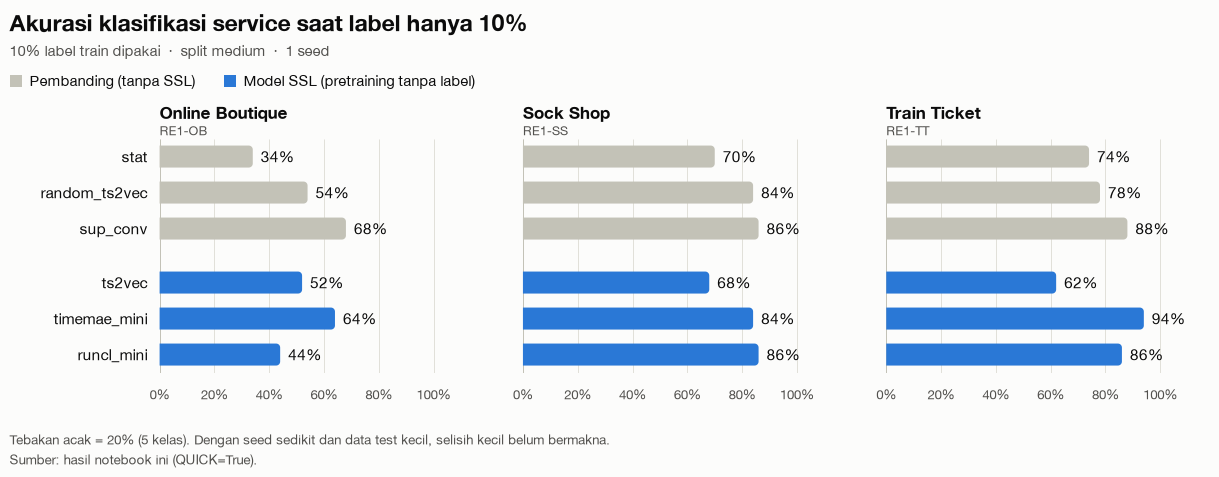

In [12]:
# Grafik akurasi pada satu pecahan label (frac), satu panel per sistem. Memakai DataFrame `results`.
from matplotlib.path import Path as MplPath          # alias: `Path` sudah dipakai pathlib di notebook ini
from matplotlib.patches import PathPatch, Rectangle

def plot_acc_at_frac(results, frac=0.1, out_path=None):
    SURFACE, INK, INK2, GRID, BASE = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
    SSL_COLOR, OTHER_COLOR = "#2a78d6", "#c3c2b7"      # biru = model SSL, abu = pembanding
    BASELINES = ["stat", "random_ts2vec", "sup_conv"]
    SSL_MODELS = ["ts2vec", "timemae_mini", "runcl_mini"]
    NAMES = {"RE1-OB": "Online Boutique", "RE1-SS": "Sock Shop", "RE1-TT": "Train Ticket"}

    acc = (results[np.isclose(results.frac, frac)]
           .groupby(["system", "model"])["acc"].mean())             # rata-rata antar seed
    systems = list(dict.fromkeys(acc.index.get_level_values("system")))
    present = set(acc.index.get_level_values("model"))
    rows = [(m, False) for m in BASELINES if m in present] + [(m, True) for m in SSL_MODELS if m in present]
    n_base = sum(1 for _, s in rows if not s)

    W, DPI, PITCH, GROUP_GAP, BAR_H, RADIUS = 1280, 96, 36, 18, 22, 4   # satuan desain = px CSS
    LEFT0, GAP, TOP, XMAX = 190, 40, 150, 1.18
    TICKS = [0, .2, .4, .6, .8, 1.0]
    panel_w = (W - LEFT0 - 40 - GAP * (len(systems) - 1)) / len(systems)
    panel_h = len(rows) * PITCH + GROUP_GAP
    H = TOP + panel_h + 111

    px, py = (lambda x: x / W), (lambda y: 1 - y / H)

    def rounded_end_bar(ax, x1v, yc, color):         # kiri persegi di baseline, kanan membulat 4px
        T = ax.transData
        x0, y0 = T.transform((0, yc)); x1, _ = T.transform((x1v, yc))
        r = min(RADIUS, BAR_H / 2, (x1 - x0) / 2)
        yb, yt = y0 - BAR_H / 2, y0 + BAR_H / 2
        a1, a2 = np.linspace(-np.pi / 2, 0, 8), np.linspace(0, np.pi / 2, 8)
        pts = [(x0, yb)]
        pts += [(x1 - r + r * np.cos(a), yb + r + r * np.sin(a)) for a in a1]
        pts += [(x1 - r + r * np.cos(a), yt - r + r * np.sin(a)) for a in a2]
        pts += [(x0, yt), (x0, yb)]                  # titik terakhir = penutup path (nilainya diabaikan)
        ax.add_patch(PathPatch(MplPath(T.inverted().transform(np.array(pts)), closed=True),
                               facecolor=color, edgecolor="none", linewidth=0, zorder=3, clip_on=False))

    with plt.rc_context({"font.family": "sans-serif",
                         "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"]}):
        fig = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI, facecolor=SURFACE)
        for k, system in enumerate(systems):
            left = LEFT0 + k * (panel_w + GAP)
            ax = fig.add_axes([px(left), py(TOP + panel_h), panel_w / W, panel_h / H], facecolor="none")
            ax.set_xlim(0, XMAX); ax.set_ylim(panel_h, 0); ax.axis("off")
            ax.vlines(TICKS, 0, panel_h, colors=GRID, linewidth=0.75, zorder=1)     # grid hairline
            ax.vlines([0], 0, panel_h, colors=BASE, linewidth=0.75, zorder=2)
            for t in TICKS:
                ax.text(t, panel_h + 14, f"{int(t * 100)}%", ha="center", va="top", fontsize=10, color=INK2)
            fig.text(px(left), py(TOP - 26), NAMES.get(system, system), fontsize=12.5, fontweight="bold",
                     color=INK, ha="left", va="center")
            fig.text(px(left), py(TOP - 8), system, fontsize=9.5, color=INK2, ha="left", va="center")
            for i, (model, is_ssl) in enumerate(rows):
                yc = i * PITCH + PITCH / 2 + (GROUP_GAP if i >= n_base else 0)
                v = acc.loc[(system, model)]
                rounded_end_bar(ax, v, yc, SSL_COLOR if is_ssl else OTHER_COLOR)
                ax.annotate(f"{round(v * 100)}%", xy=(v, yc), xytext=(8, 0), textcoords="offset pixels",
                            ha="left", va="center", fontsize=11.5, color=INK, zorder=4)
                if k == 0:
                    ax.annotate(model, xy=(0, yc), xytext=(-12, 0), textcoords="offset pixels",
                                ha="right", va="center", fontsize=11.5, color=INK)

        n_seed, n_class = results.seed.nunique(), SYS_INFO[systems[0]]["n_class"]
        fig.text(px(40), py(34), f"Akurasi klasifikasi service saat label hanya {frac:.0%}", fontsize=17,
                 fontweight="bold", color=INK, ha="left", va="center")
        fig.text(px(40), py(62), f"{frac:.0%} label train dipakai  ·  split {CFG['SPLIT']}  ·  {n_seed} seed",
                 fontsize=11, color=INK2, ha="left", va="center")
        lx = 40
        for color, label in [(OTHER_COLOR, "Pembanding (tanpa SSL)"), (SSL_COLOR, "Model SSL (pretraining tanpa label)")]:
            fig.patches.append(Rectangle((px(lx), py(98)), 12 / W, 12 / H, transform=fig.transFigure,
                                         facecolor=color, edgecolor="none"))
            t = fig.text(px(lx + 20), py(92), label, fontsize=11, color=INK, ha="left", va="center")
            fig.canvas.draw()
            lx += 20 + t.get_window_extent().width + 28
        fig.text(px(40), py(H - 44), f"Tebakan acak = {1 / n_class:.0%} ({n_class} kelas). Dengan seed sedikit dan data test kecil, selisih kecil belum bermakna.",
                 fontsize=10, color=INK2, ha="left", va="center")
        fig.text(px(40), py(H - 24), f"Sumber: hasil notebook ini (QUICK={CFG['QUICK']}).",
                 fontsize=10, color=INK2, ha="left", va="center")
        if out_path:
            fig.savefig(out_path, dpi=DPI * 2, facecolor=SURFACE)
        plt.show()

plot_acc_at_frac(results, frac=0.1, out_path="grafik_akurasi_label10persen.png")

### Grafik tiga metrik pada label sedikit

Sama seperti panel kanan pada sel hasil (accuracy, macro-F1, Top-3 per model), tetapi untuk satu pecahan label (`frac`) dan disertai tabel nilai lengkap. Ubah `frac` di baris terakhir sel berikut untuk pecahan lain.

In [ ]:
# Grafik tiga metrik (accuracy, macro-F1, Top-3) per model pada satu pecahan label (frac), seperti panel kanan di sel hasil.
from matplotlib.path import Path as MplPath          # alias: `Path` sudah dipakai pathlib di notebook ini
from matplotlib.patches import PathPatch, Rectangle

def plot_metrics_at_frac(results, frac=0.1, out_path=None):
    SURFACE, INK, INK2, GRID, BASE = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
    METRICS = [("acc", "Accuracy", "#2a78d6"), ("macro_f1", "Macro-F1", "#eb6834"), ("top3", "Top-3 accuracy", "#1baf7a")]
    LABELED = {"acc", "top3"}                          # macro-F1 mirip accuracy; nilainya ada di tabel
    BASELINES = ["stat", "random_ts2vec", "sup_conv"]
    SSL_MODELS = ["ts2vec", "timemae_mini", "runcl_mini"]
    NAMES = {"RE1-OB": "Online Boutique", "RE1-SS": "Sock Shop", "RE1-TT": "Train Ticket"}

    cols = [m for m, _, _ in METRICS]
    tab = (results[np.isclose(results.frac, frac)]
           .groupby(["system", "model"])[cols].mean())                     # rata-rata antar seed
    systems = list(dict.fromkeys(tab.index.get_level_values("system")))
    present = set(tab.index.get_level_values("model"))
    blocks = [("Pembanding", [m for m in BASELINES if m in present]),
              ("Model SSL", [m for m in SSL_MODELS if m in present])]

    W, DPI, BAR_H, BAR_GAP, GROUP_PAD, CAPTION, RADIUS = 1280, 96, 14, 2, 14, 22, 4   # satuan desain = px CSS
    LEFT0, GAP, TOP, XMAX = 190, 40, 150, 1.18
    TICKS = [0, .2, .4, .6, .8, 1.0]
    group_h = len(METRICS) * (BAR_H + BAR_GAP) - BAR_GAP
    layout, y = [], 0                                  # (model, y atas grup, apakah SSL) + keterangan blok
    captions = []
    for b, (title, models) in enumerate(blocks):
        captions.append((title, y)); y += CAPTION
        for m in models:
            layout.append((m, y, b == 1)); y += group_h + GROUP_PAD
        y += 6
    panel_h = y - GROUP_PAD - 6
    panel_w = (W - LEFT0 - 40 - GAP * (len(systems) - 1)) / len(systems)
    H = TOP + panel_h + 111
    px, py = (lambda x: x / W), (lambda y: 1 - y / H)

    def rounded_end_bar(ax, x1v, yc, color):         # kiri persegi di baseline, kanan membulat 4px
        T = ax.transData
        x0, y0 = T.transform((0, yc)); x1, _ = T.transform((x1v, yc))
        r = min(RADIUS, BAR_H / 2, (x1 - x0) / 2)
        yb, yt = y0 - BAR_H / 2, y0 + BAR_H / 2
        a1, a2 = np.linspace(-np.pi / 2, 0, 8), np.linspace(0, np.pi / 2, 8)
        pts = [(x0, yb)]
        pts += [(x1 - r + r * np.cos(a), yb + r + r * np.sin(a)) for a in a1]
        pts += [(x1 - r + r * np.cos(a), yt - r + r * np.sin(a)) for a in a2]
        pts += [(x0, yt), (x0, yb)]                  # titik terakhir = penutup path (nilainya diabaikan)
        ax.add_patch(PathPatch(MplPath(T.inverted().transform(np.array(pts)), closed=True),
                               facecolor=color, edgecolor="none", linewidth=0, zorder=3, clip_on=False))

    with plt.rc_context({"font.family": "sans-serif",
                         "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"]}):
        fig = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI, facecolor=SURFACE)
        for k, system in enumerate(systems):
            left = LEFT0 + k * (panel_w + GAP)
            ax = fig.add_axes([px(left), py(TOP + panel_h), panel_w / W, panel_h / H], facecolor="none")
            ax.set_xlim(0, XMAX); ax.set_ylim(panel_h, 0); ax.axis("off")
            ax.vlines(TICKS, 0, panel_h, colors=GRID, linewidth=0.75, zorder=1)     # grid hairline
            ax.vlines([0], 0, panel_h, colors=BASE, linewidth=0.75, zorder=2)
            for t in TICKS:
                ax.text(t, panel_h + 14, f"{int(t * 100)}%", ha="center", va="top", fontsize=10, color=INK2)
            fig.text(px(left), py(TOP - 26), NAMES.get(system, system), fontsize=12.5, fontweight="bold",
                     color=INK, ha="left", va="center")
            fig.text(px(left), py(TOP - 8), system, fontsize=9.5, color=INK2, ha="left", va="center")
            for model, y0, _ in layout:
                for j, (key, _, color) in enumerate(METRICS):
                    yc = y0 + j * (BAR_H + BAR_GAP) + BAR_H / 2
                    v = tab.loc[(system, model), key]
                    rounded_end_bar(ax, v, yc, color)
                    if key in LABELED:
                        ax.annotate(f"{round(v * 100)}%", xy=(v, yc), xytext=(6, 0), textcoords="offset pixels",
                                    ha="left", va="center", fontsize=9.5, color=INK, zorder=4)
                if k == 0:
                    ax.annotate(model, xy=(0, y0 + group_h / 2), xytext=(-12, 0), textcoords="offset pixels",
                                ha="right", va="center", fontsize=11.5, color=INK)
            if k == 0:
                for title, ycap in captions:
                    ax.annotate(title.upper(), xy=(0, ycap + 8), xytext=(-12, 0), textcoords="offset pixels",
                                ha="right", va="center", fontsize=8.5, color=INK2, fontweight="bold")

        n_seed = results.seed.nunique()
        fig.text(px(40), py(34), f"Accuracy, macro-F1, dan Top-3 saat label hanya {frac:.0%}", fontsize=17,
                 fontweight="bold", color=INK, ha="left", va="center")
        fig.text(px(40), py(62), f"{frac:.0%} label train dipakai  ·  split {CFG['SPLIT']}  ·  {n_seed} seed",
                 fontsize=11, color=INK2, ha="left", va="center")
        lx = 40
        for _, label, color in METRICS:
            fig.patches.append(Rectangle((px(lx), py(98)), 12 / W, 12 / H, transform=fig.transFigure,
                                         facecolor=color, edgecolor="none"))
            t = fig.text(px(lx + 20), py(92), label, fontsize=11, color=INK, ha="left", va="center")
            fig.canvas.draw()
            lx += 20 + t.get_window_extent().width + 28
        fig.text(px(40), py(H - 44), "Angka hanya untuk accuracy dan Top-3; macro-F1 mengikuti accuracy (nilai lengkap di tabel notebook).",
                 fontsize=10, color=INK2, ha="left", va="center")
        fig.text(px(40), py(H - 24), f"Dengan seed sedikit dan data test kecil, selisih kecil belum bermakna. Sumber: hasil notebook ini (QUICK={CFG['QUICK']}).",
                 fontsize=10, color=INK2, ha="left", va="center")
        if out_path:
            fig.savefig(out_path, dpi=DPI * 2, facecolor=SURFACE)
        plt.show()
    display(tab.round(3).unstack(0).swaplevel(axis=1).sort_index(axis=1))        # tabel pendamping (nilai lengkap)

plot_metrics_at_frac(results, frac=0.1, out_path="grafik_metrik_label10persen.png")

## 8. (Opsional) RUN-native via RCAEval

RUN asli (neural Granger causal discovery + PageRank) tersedia sebagai baseline di paket `RCAEval`.
RUN melatih model **per case** dan menghasilkan *ranking* metrik, bukan kelas. Di sini ranking itu dipetakan ke service
(prefix nama metrik) lalu diukur Top-1/Top-3 terhadap `root_cause_service`. Tanpa label sama sekali.

Setelan di bawah (jendela waktu ±10 menit di sekitar `inject_time`, jumlah case) adalah pilihan saya.
Tanda tangan fungsi `run(...)` bisa berbeda antar versi RCAEval, jadi dicoba beberapa bentuk pemanggilan.
Dibatasi `RUN_MAX_CASES` karena lambat.

In [13]:
RUN_NATIVE        = False   # ganti True setelah `pip install "RCAEval[default]"`
RUN_MAX_CASES     = 10
RUN_HALF_WINDOW_S = 600

def run_native_eval(case_ids):
    from RCAEval.e2e import run as rca_run
    from RCAEval.utility import read_metrics
    rows = []
    for i in tqdm(list(case_ids), desc="RUN-native"):
        case = DATA["idx"].case.iloc[i]
        try:
            df = read_metrics(str(Path(DATA_ROOT) / case))
            df = df.loc[:, ~df.columns.duplicated()]
            inj_t = int(df["time"].iloc[min(DATA["inj"][i], len(df) - 1)])
            df = df[(df["time"] >= inj_t - RUN_HALF_WINDOW_S) & (df["time"] <= inj_t + RUN_HALF_WINDOW_S)]
            try:
                ranks = rca_run(df, inj_t, dataset=CFG["DATASET"].lower())["ranks"]
            except TypeError:
                ranks = rca_run(df, inj_t)["ranks"]
            svc_rank = [s for s in dict.fromkeys(service_of(str(m)) for m in ranks)
                        if s in DATA["classes"]]
            rows.append(dict(case=case, truth=DATA["y"][i], top1=svc_rank[:1] == [DATA["y"][i]],
                             top3=DATA["y"][i] in svc_rank[:3]))
        except Exception as e:
            rows.append(dict(case=case, truth=DATA["y"][i], top1=False, top3=False, error=str(e)[:80]))
    return pd.DataFrame(rows)

run_native_df = None
if RUN_NATIVE and not CFG["DRY_RUN"]:
    outs = []
    for name in CFG["SYSTEMS"]:
        prepare_system(name)
        _, _, te_run = make_splits("medium")[0]
        pick = np.random.default_rng(0).choice(te_run, min(RUN_MAX_CASES, len(te_run)), replace=False)
        outs.append(run_native_eval(pick).assign(system=name))
    run_native_df = pd.concat(outs, ignore_index=True)
    display(run_native_df)
    for name, g in run_native_df.groupby("system", sort=False):
        print(f"RUN-native {name}: Top-1={g.top1.mean():.3f}  Top-3={g.top3.mean():.3f}  (n={len(g)})")
else:
    print("RUN-native dilewati (set RUN_NATIVE=True dan DRY_RUN=False untuk menjalankan).")

RUN-native dilewati (set RUN_NATIVE=True dan DRY_RUN=False untuk menjalankan).


## 9. Kesimpulan

In [14]:
# Kesimpulan otomatis per sistem dari hasil run Anda (tidak ada angka yang ditulis manual).
def auto_conclusion(results, system, run_native_df=None):
    results = results[results.system == system]
    if len(results) == 0:
        print("Belum ada hasil untuk disimpulkan."); return
    ssl = [m for m in ["ts2vec", "timemae_mini", "runcl_mini"] if m in set(results.model)]
    fmax, fmin = results.frac.max(), results.frac.min()
    tab = results.groupby(["model", "frac"])["acc"].agg(["mean", "std"]).fillna(0)
    n_seed = results.seed.nunique(); n_class = SYS_INFO[system]["n_class"]; chance = 1 / n_class
    lines = [f"Sistem {system}, split={CFG['SPLIT']}, "
             f"{n_class} kelas (chance={chance:.2f}), {n_seed} seed."]
    best = tab.xs(fmax, level="frac")["mean"].sort_values(ascending=False)
    lines.append(f"Label penuh: terbaik = {best.index[0]} (acc {best.iloc[0]:.3f}); urutan: " +
                 ", ".join(f"{m} {v:.3f}" for m, v in best.items()) + ".")
    best_lo = tab.xs(fmin, level="frac")["mean"].sort_values(ascending=False)
    lines.append(f"Label sedikit (frac={fmin}): terbaik = {best_lo.index[0]} (acc {best_lo.iloc[0]:.3f}).")
    for ref in ["random_ts2vec", "stat"]:
        if ref in tab.index.get_level_values(0):
            for m in ssl:
                for f in (fmin, fmax):
                    d = tab.loc[(m, f), "mean"] - tab.loc[(ref, f), "mean"]
                    sd = max(tab.loc[(m, f), "std"], tab.loc[(ref, f), "std"])
                    verdict = "lebih baik" if d > sd and d > 0 else ("lebih buruk" if -d > sd else "tidak beda jelas")
                    lines.append(f"{m} vs {ref} @frac={f}: selisih {d:+.3f} ({verdict}, ambang = 1 std).")
    if "sup_conv" in tab.index.get_level_values(0):
        for m in ssl:
            d = tab.loc[(m, fmin), "mean"] - tab.loc[("sup_conv", fmin), "mean"]
            lines.append(f"{m} vs supervised dari nol @frac={fmin}: selisih {d:+.3f}.")
    rn = run_native_df[run_native_df.system == system] if run_native_df is not None else None
    if rn is not None and len(rn):
        lines.append(f"RUN-native (tanpa label, n={len(rn)}): Top-1={rn.top1.mean():.3f}, "
                     f"Top-3={rn.top3.mean():.3f}.")
    if n_seed < 3:
        lines.append("PERHATIAN: seed < 3, selisih kecil jangan dianggap bermakna.")
    print("\n".join("- " + l for l in lines))

for name in results.system.unique():
    print(f"\n### {name}")
    auto_conclusion(results, name, run_native_df)


### RE1-OB
- Sistem RE1-OB, split=medium, 5 kelas (chance=0.20), 1 seed.
- Label penuh: terbaik = runcl_mini (acc 1.000); urutan: runcl_mini 1.000, stat 1.000, sup_conv 1.000, random_ts2vec 0.980, ts2vec 0.960, timemae_mini 0.940.
- Label sedikit (frac=0.1): terbaik = sup_conv (acc 0.680).
- ts2vec vs random_ts2vec @frac=0.1: selisih -0.020 (lebih buruk, ambang = 1 std).
- ts2vec vs random_ts2vec @frac=1.0: selisih -0.020 (lebih buruk, ambang = 1 std).
- timemae_mini vs random_ts2vec @frac=0.1: selisih +0.100 (lebih baik, ambang = 1 std).
- timemae_mini vs random_ts2vec @frac=1.0: selisih -0.040 (lebih buruk, ambang = 1 std).
- runcl_mini vs random_ts2vec @frac=0.1: selisih -0.100 (lebih buruk, ambang = 1 std).
- runcl_mini vs random_ts2vec @frac=1.0: selisih +0.020 (lebih baik, ambang = 1 std).
- ts2vec vs stat @frac=0.1: selisih +0.180 (lebih baik, ambang = 1 std).
- ts2vec vs stat @frac=1.0: selisih -0.040 (lebih buruk, ambang = 1 std).
- timemae_mini vs stat @frac=0.1: selisih +0.

### Kesimpulan akhir

**Yang dibuktikan notebook ini**
- Ada pipeline SSL end-to-end untuk RCAEval dengan satu protokol yang sama untuk tiga keluarga model
  (TS2Vec, TimeMAE-style, RUN-style): preprocessing identik, split berkelompok anti-bocor, dan linear probe yang sama.
  Karena itu perbedaan skor mencerminkan kualitas representasi, bukan perbedaan prosedur.
- Pretraining dianggap **bermanfaat** hanya jika memenuhi ketiganya: (1) mengalahkan encoder random-init
  dengan arsitektur sama (`random_ts2vec`), (2) mengalahkan baseline fitur statistik sederhana, dan
  (3) keunggulannya terlihat pada label sedikit. Sel kesimpulan otomatis di atas menguji tepat ketiga hal ini
  dengan ambang 1 standar deviasi antar seed.

**Cara membaca hasil**
- Label penuh dan label sedikit menjawab pertanyaan berbeda: label penuh mengukur kualitas representasi,
  label sedikit mengukur manfaat SSL. Bila model supervised dari nol menyamai SSL di label sedikit,
  manfaat SSL pada dataset sekecil ini belum terbukti.
- Split `hard` (leave-one-fault-out) adalah ukuran generalisasi yang paling jujur. Skor tinggi di `easy`
  dengan penurunan tajam di `hard` berarti model mengenali pola fault tertentu, bukan service penyebabnya.
- RUN-native tidak memakai label dan outputnya ranking, jadi jangan dibandingkan angka demi angka dengan
  linear probe tanpa menyebut perbedaan ini.

**Keterbatasan**
- Data kecil (puluhan case per kelas) dan repetisi hampir duplikat: varians antar split besar, gunakan >= 3 seed.
- TimeMAE-mini dan RUN-adapted adalah re-implementasi/adaptasi saya. Hasilnya bukan representasi resmi TimeMAE atau RUN;
  untuk klaim publikasi, ulangi dengan repo resmi.
- Kelas hanya level service dan label spesifik per sistem, sehingga tidak ada transfer lintas sistem.
  Tiap sistem RE1 punya 5 kelas dan dijalankan terpisah, jadi angka antar sistem tidak ekuivalen (kelas dan jumlah kanal berbeda).
- Kanal service non-kelas (mis. `frontend`) dan kanal DB pendamping (`carts-db`, `ts-*-mongo`) dibuang (`PRUNE_CHANNELS`).
  Ini mempersempit input ke service kandidat saja; pengaruhnya belum diuji.
- Pilihan preprocessing (normalisasi dengan statistik periode normal, window 128 detik, clip +-10, pengisian kolom hilang dengan 0)
  memengaruhi hasil dan layak diuji sebagai ablation.

**Langkah lanjut**
1. Jalankan `QUICK=False` dengan >= 3 seed untuk `easy`, `medium`, dan `hard` pada ketiga sistem RE1.
2. Ablation pembuangan kanal (`PRUNE_CHANNELS=True` vs `False`). RE2 dan RE3 di luar cakupan.
3. Ablation: panjang window, `CASE_REPR` (`diff` vs `fault` vs `concat`), mask ratio dan ukuran patch.
4. Tambahkan pipeline B (embedding per service lalu ranking) agar sebanding dengan metrik RCA (Avg@k).
5. Ganti TimeMAE-mini dengan repo resmi dan RUN-adapted dengan RUN penuh sebagai konfirmasi.